In [358]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [359]:
import pandas as pd

import seaborn as sns
import matplotlib as mpl
import matplotlib.pyplot as plt
import os

In [360]:
from plotting_ts_tools import (
    calculate_anomaly,
    line_plot,
    line_plot_min_max,
    cleanup,
    adjust_names,
    adjust_length,
    line_plot_anomaly,
    load_era5_csv,
    load_rcms_csv
)

In [361]:
# Define Variables
# 50 mm sind sehr wenige
# TR, Regcm hat zu viele sieht komisch aus
#index='R20mm' 
#index= 'DD'
index= 'TG'
#index='SU35'
#index='SU40'
#index='TR26'
#index='RRm'

#country='Togo'
#country='Burkina Faso'
country='Ivory Coast'
timestep='year'
longnameK='mean temperature [K]'

#longname='number of days with pr > 20 mm per day'  
#longname='number of dry days'  
longname='mean temperature [°C]'
#longname='number of days with Tmax > 35°C'
#longname='number of days with Tmax > 40°C'
#longname='number of tropical nights with Tmin > 26°C'
#longname='mean daily precipitation amount [mm/day]'

In [362]:
# Load the CSV file
path='/work/ch0636/g300047/cicles/climate_fact_data/spavg_afr22/'+index
file_name='climdexCORDEX_AFR22_'+index+'_'+timestep+'_weighted_means.csv'
file_path = os.path.join(path,file_name)
data = pd.read_csv(file_path)

In [363]:
# Add ERA5
path='/work/ch0636/g300047/cicles/climate_fact_data/spavg_era5/'+index
file_name='climdexERA5_'+index+'_'+timestep+'_weighted_means.csv'
era5_path = os.path.join(path,file_name)
era5data = pd.read_csv(era5_path)

In [364]:
# define output path and filename
outputpath='/work/ch0636/g300047/cicles/factsheet_africa/PLOTS/AFR22_timeseries'
#outfile = os.path.join(outputpath,index+'_'+timestep+'_line_plot_sce_color_min_max.png')

if not os.path.exists(outputpath):
    os.makedirs(outputpath)

In [365]:
#cut_data=load_rcms_csv(file_path, country, index, longname, start_date='1971-01-01', end_date='2098-12-31', longnameK=None)
if index == 'TG':
    cut_data=load_rcms_csv(file_path, country, index, longname, start_date='1971-01-01', end_date='2098-12-31', longnameK=longnameK)
else:
    cut_data=load_rcms_csv(file_path, country, index, longname, start_date='1971-01-01', end_date='2098-12-31', longnameK=None)

In [366]:
# prepare era5 data
era5_cut=load_era5_csv(era5_path, country, index, longname, start_date='1971-01-01', longnameK=longnameK)

In [367]:
longname

'mean temperature [°C]'

Plotting column:  mean temperature [°C]
year mean temperature [°C]
year mean temperature [°C]
Saved plot to:  /work/ch0636/g300047/cicles/factsheet_africa/PLOTS/AFR22_timeseries/line_plot_min_max_TG_year_Ivory_Coast.png


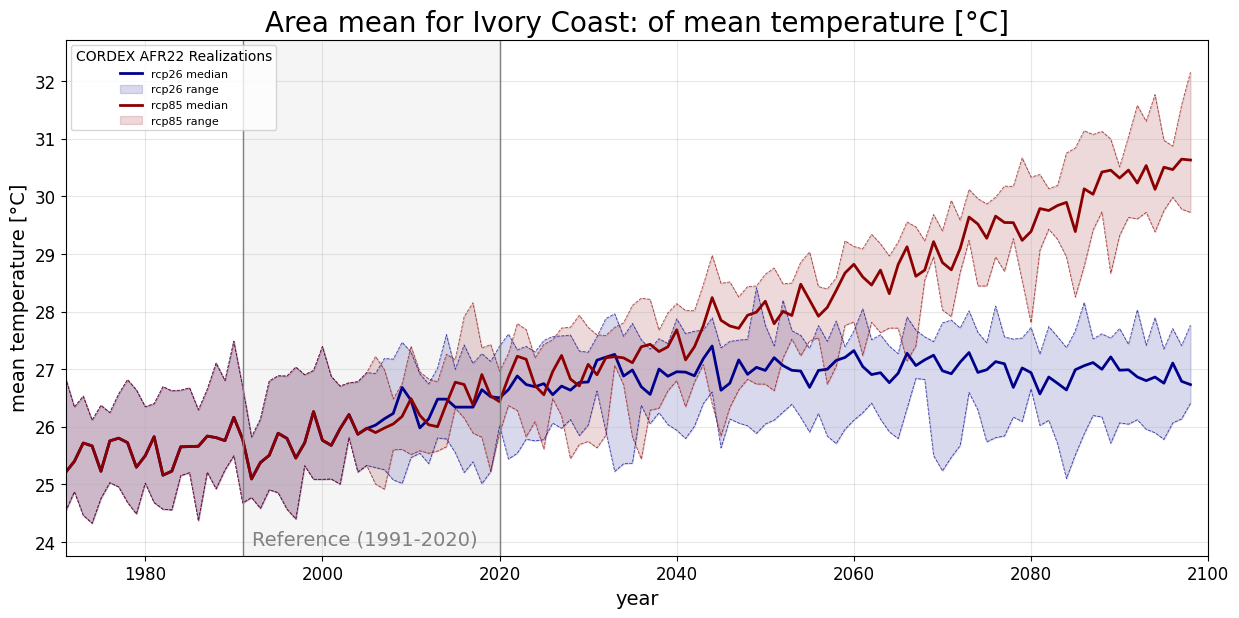

Plotting column:  mean temperature [°C]
year mean temperature [°C]
year mean temperature [°C]
Saved plot to:  /work/ch0636/g300047/cicles/factsheet_africa/PLOTS/AFR22_timeseries/line_plot_min_max_TG_year_Ivory_Coast_ERA5.png


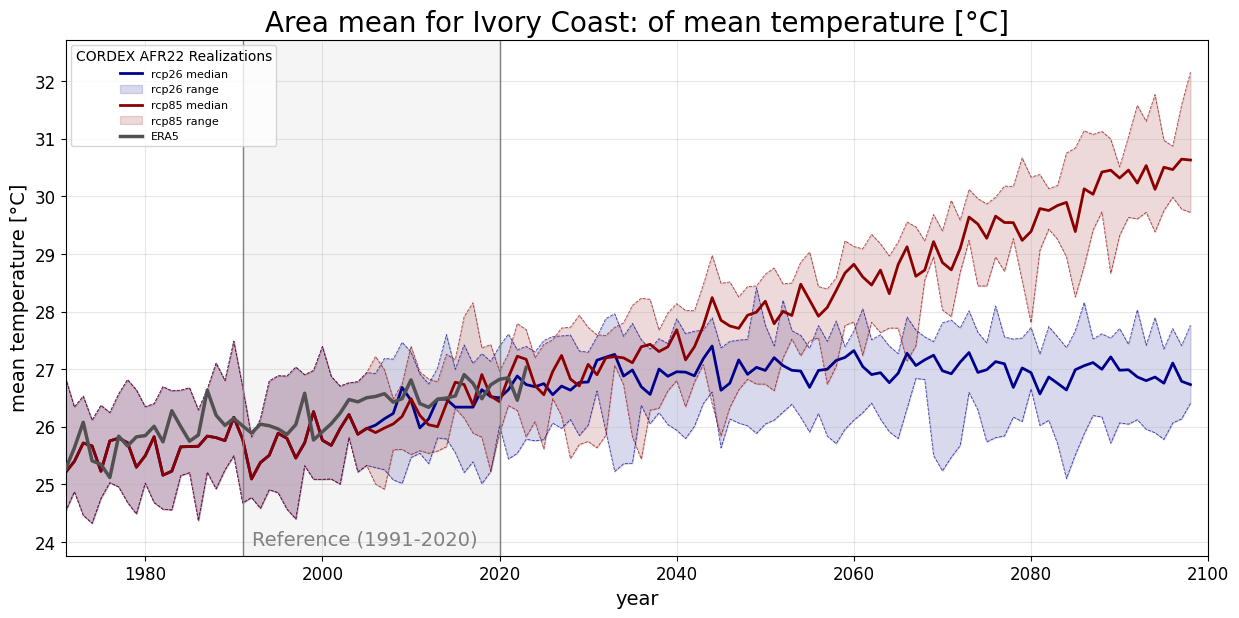

In [368]:
# You can chose if you like to add ERA5 or not
line_plot_min_max(cut_data,'year',longname,index,outputpath,country)#, ylim=(23,37))
line_plot_min_max(cut_data,'year',longname,index,outputpath,country, dfera5=era5_cut)#, ylim=(23,37))


In [369]:
# calculate anomalies
# Returns dataframe with columns: anomaly, running_mean_10yr, running_mean_30yr
df = calculate_anomaly(cut_data, '1991-01-01', '2020-12-31', longname)
#df.head()

In [370]:
df_era5 = calculate_anomaly(era5_cut, '1991-01-01', '2020-12-31', longname)
#df_era5.head()

In [371]:
df.columns

Index(['realization', 'year', 'region', 'mean temperature [K]', 'ci_name',
       'ci_frequency', 'standard_name', 'units', 'mean temperature [°C]',
       'GCM', 'RCM', 'scenario', 'mean_ref', 'anomaly', 'running_mean_10yr',
       'running_mean_30yr'],
      dtype='object')

file liegt:  /work/ch0636/g300047/cicles/factsheet_africa/PLOTS/AFR22_timeseries/line_plot_scenario_min_max_year_TG_anomaly_Ivory_Coast.png


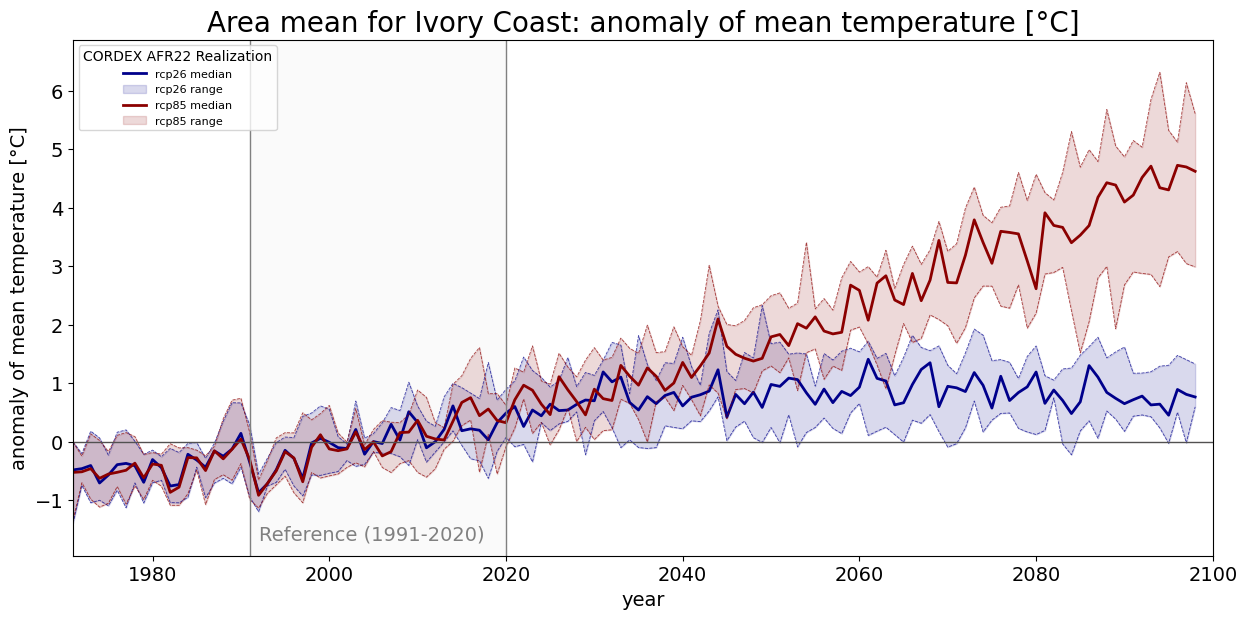

In [372]:
# make line plot with or without ERA5
#  make line plot of anomaly
# you can chose if you like to group by scenario or not
# you can chose if you like:
    # anomaly or running_mean_10yr or running_mean_30yr

#line_plot_anomaly(df, 'year', 'anomaly', outputpath, 'scenario', country, index, longname)
#line_plot_anomaly(df, 'year', 'anomaly', outputpath, 'scenario_min_max', country, index, longname) #,ylim=(-3,10))
#line_plot_anomaly(df, 'year', 'anomaly', outputpath, 'model', country, index, longname)
#line_plot_anomaly(df, 'year', 'running_mean_10yr', outputpath, 'model', country, index,longname)
#line_plot_anomaly(df, 'year', 'running_mean_30yr', outputpath, 'model', country, index,longname)
line_plot_anomaly(df, 'year', 'anomaly', outputpath, 'scenario_min_max', country, index, longname)
#line_plot_anomaly(df, 'year', 'anomaly', outputpath, 'scenario_min_max', country, index, longname, era5=df_era5)